In [1]:
# Import all needed ilbraries for EDA
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

# Set project root
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load data
train = pd.read_csv(PROJECT_ROOT / "data/raw/train.csv")
test = pd.read_csv(PROJECT_ROOT / "data/raw/test.csv")

with open(PROJECT_ROOT / "data/raw/music_app.json", encoding="utf-8") as f:
    music_data = json.load(f)

# First overview
print("Train shape:", train.shape)
print("Test shape:", test.shape)

display(train.head())
display(train.info())

Train shape: (30000, 32)
Test shape: (20000, 31)


,row_id,user_id,music_app_user_id,age,education,spending_capacity_band,home_city,home_lat,home_lon,stated_favourite_genre,...,sale_opened_at,prediction_at,ticket_price,booking_fee,discount_pct,event_page_visits_7d,wishlisted,travel_search_city,travel_search_arrival,buy
0,R2F019957,U2CFDCAAD,M1B01D2D7,23,postgraduate,2,Nantes,47.218,-1.554,pop,...,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,75.0,9.50,0,0.0,1,NaN,NaN,0
1,R0804D93A,U1FC01010,M1B2C63CC,51,undergraduate,5,Bordeaux,44.838,-0.579,pop,...,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,85.0,10.10,0,3.0,0,NaN,NaN,1
2,R367FE81E,U0C605712,M3AEF638D,32,secondary,1,Lyon,45.764,4.835,classical,...,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,175.0,15.50,20,1.0,1,NaN,NaN,0
3,R344BBE29,U25D1DD8A,M00C580ED,24,secondary,2,Paris,48.857,2.352,jazz_funk,...,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,84.0,10.04,0,1.0,1,NaN,NaN,1
4,R004ABDEB,U1600BC92,M29AC37E6,21,secondary,3,Bordeaux,44.838,-0.579,NaN,...,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,95.0,10.70,0,0.0,0,Rennes,2026-12-28,1


<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   row_id                   30000 non-null  str    
 1   user_id                  30000 non-null  str    
 2   music_app_user_id        28305 non-null  str    
 3   age                      30000 non-null  int64  
 4   education                30000 non-null  str    
 5   spending_capacity_band   30000 non-null  int64  
 6   home_city                30000 non-null  str    
 7   home_lat                 30000 non-null  float64
 8   home_lon                 30000 non-null  float64
 9   stated_favourite_genre   25375 non-null  str    
 10  past_purchase_count      30000 non-null  int64  
 11  first_timer              30000 non-null  int64  
 12  typical_ticket_spend     21760 non-null  float64
 13  usual_booking_lead_days  21760 non-null  float64
 14  concert_id               30000 no

None

In [ ]:
# Missing values in the training dataset
missing_train = pd.DataFrame({
    "Missing Count": train.isna().sum(),
    "Missing (%)": train.isna().mean() * 100
})

# Sort features by missing percentage
missing_train = missing_train.sort_values(
    by="Missing (%)",
    ascending=False
)

# Display missing statistics
display(missing_train.round(2))

,Missing Count,Missing (%)
travel_search_arrival,22496,74.99
travel_search_city,22496,74.99
typical_ticket_spend,8240,27.47
usual_booking_lead_days,8240,27.47
stated_favourite_genre,4625,15.42
music_app_user_id,1695,5.65
event_page_visits_7d,863,2.88
education,0,0.00
home_lat,0,0.00
home_city,0,0.00


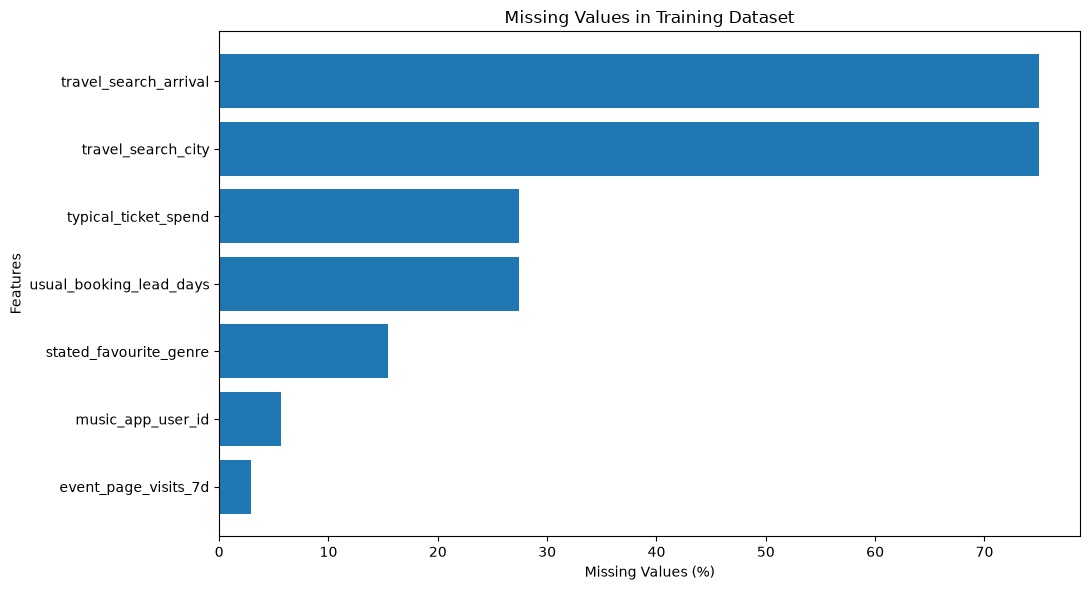

In [ ]:
# Plot feautres with missing values and how much % are missing
missing_plot = missing_train[
    missing_train["Missing (%)"] > 0
]

plt.figure(figsize=(11, 6))

plt.barh(
    missing_plot.index,
    missing_plot["Missing (%)"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.title("Missing Values in Training Dataset")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
# Compare missing values for train and test
missing_comparison = pd.DataFrame({
    "Train Missing (%)": train.isna().mean() * 100,
    "Test Missing (%)": test.isna().mean() * 100
})

# Remove target variable because it is not in test
missing_comparison = missing_comparison.drop(index="buy",errors="ignore")

missing_comparison["Difference (pp)"] = (missing_comparison["Test Missing (%)"] - missing_comparison["Train Missing (%)"])

display(missing_comparison.sort_values(by="Difference (pp)", key=abs,ascending=False).round(2))

,Train Missing (%),Test Missing (%),Difference (pp)
stated_favourite_genre,15.42,13.92,-1.49
typical_ticket_spend,27.47,28.88,1.41
usual_booking_lead_days,27.47,28.88,1.41
event_page_visits_7d,2.88,3.15,0.27
travel_search_arrival,74.99,74.78,-0.21
travel_search_city,74.99,74.78,-0.21
music_app_user_id,5.65,5.72,0.08
discount_pct,0.00,0.00,0.00
concert_id,0.00,0.00,0.00
first_timer,0.00,0.00,0.00


In [ ]:
# Check for duplicates in test and train
print("Duplicate rows in train:", train.duplicated().sum())
print("Duplicate rows in test:", test.duplicated().sum())

Duplicate rows in train: 0
Duplicate rows in test: 0


In [ ]:
# Are there duplicate entries for user-concert combination?
key_columns = ["user_id", "concert_id"]

if all(col in train.columns for col in key_columns):
    print(
        "Duplicate user-concert pairs:",
        train.duplicated(subset=key_columns).sum()
    )

Duplicate user-concert pairs: 0


In [7]:
# Select numerical features
numerical_columns = train.select_dtypes(include=np.number).columns

# Check for infinite values
infinite_counts = pd.Series(np.isinf(train[numerical_columns]).sum(), index=numerical_columns, name="Infinite Count")

# Display number of infinite value
display(infinite_counts[infinite_counts > 0])

# Check min and max values
display(train[numerical_columns].agg(["min", "max"]).T)

Series([], Name: Infinite Count, dtype: int64)

,min,max
age,18.000,65.000
spending_capacity_band,1.000,5.000
home_lat,43.604,50.630
home_lon,-1.678,7.752
past_purchase_count,0.000,13.000
first_timer,0.000,1.000
typical_ticket_spend,20.870,786.915
usual_booking_lead_days,3.500,497.000
venue_lat,44.838,50.630
venue_lon,-1.554,4.835


In [ ]:
# Compare datatypes for train and test. (There shouldnt be a mismatch)
dtype_comparison = pd.DataFrame({"Train dtype": train.dtypes.astype(str),"Test dtype": test.dtypes.astype(str)})

display(dtype_comparison)

# Compare feature sets
train_features = set(train.columns) - {"buy"}
test_features = set(test.columns)

print("Only in train:", train_features - test_features)
print("Only in test:", test_features - train_features)

,Train dtype,Test dtype
age,int64,int64
artist_id,str,str
artist_name,str,str
booking_fee,float64,float64
buy,int64,NaN
concert_at,str,str
concert_id,str,str
discount_pct,int64,int64
education,str,str
event_page_visits_7d,float64,float64


Only in train: set()
Only in test: set()


In [ ]:
# Does the missingness of values let us to conclude something about the búying
missing_target_results = []

for col in train.columns.drop("buy"):

    missing = train[col].isna()

    if missing.any() and (~missing).any():

        missing_target_results.append({
            "Feature": col,
            "Missing (%)": missing.mean() * 100,
            "Buy Rate (Missing)": train.loc[missing, "buy"].mean(),
            "Buy Rate (Present)": train.loc[~missing, "buy"].mean()
        })

missing_target_df = pd.DataFrame(missing_target_results)

missing_target_df["Buy Rate Difference"] = (missing_target_df["Buy Rate (Missing)"] - missing_target_df["Buy Rate (Present)"])

display(missing_target_df.sort_values(by="Buy Rate Difference",key=abs,ascending=False).round(3))

,Feature,Missing (%),Buy Rate (Missing),Buy Rate (Present),Buy Rate Difference
0,music_app_user_id,5.650,0.494,0.327,0.167
5,travel_search_city,74.987,0.321,0.383,-0.063
6,travel_search_arrival,74.987,0.321,0.383,-0.063
3,usual_booking_lead_days,27.467,0.367,0.325,0.042
2,typical_ticket_spend,27.467,0.367,0.325,0.042
4,event_page_visits_7d,2.877,0.308,0.337,-0.029
1,stated_favourite_genre,15.417,0.346,0.334,0.011


Key Findings:

1. Shape of Data: Train shape: (30000, 32)
                  Test shape: (20000, 31)

2. Missing Values train data: Column name               # Obs.  % Data
                              travel_search_arrival	    22496	74.99%
                              travel_search_city	    22496	74.99%
                              typical_ticket_spend	    8240	27.47%
                              usual_booking_lead_days	8240	27.47%
                              stated_favourite_genre	4625	15.42%
                              music_app_user_id	        1695	5.65%
                              event_page_visits_7d	    863	    2.88%

3. Difference Missing Values Train and Test: Column name                Train   Test    Delta
                                             stated_favourite_genre	    15.42%	13.92%	-1.49%
                                             typical_ticket_spend	    27.47%	28.88%	1.41%
                                             usual_booking_lead_days	27.47%	28.88%	1.41%
                                             event_page_visits_7d	    2.88%	3.15%	0.27%
                                             travel_search_arrival	    74.99%	74.78%	-0.21%
                                             travel_search_city	        74.99%	74.78%	-0.21%
                                             music_app_user_id	        5.65%	5.72%	0.08%

4. Duplicate Rows in Train and Test: Duplicate rows in train: 0
                                     Duplicate rows in test: 0

5. Duplicate user-consert entries: Duplicate user-concert pairs: 0

6. Min-Max for each column: Column name             Min     Max
                            age	                    18.000  65.000
                            spending_capacity_band	1.000	5.000
                            home_lat	            43.604	50.630
                            home_lon	            -1.678	7.752
                            past_purchase_count	    0.000	13.000
                            first_timer	            0.000	1.000
                            typical_ticket_spend	20.870	786.915
                            usual_booking_lead_days	3.500	497.000
                            venue_lat	            44.838	50.630
                            venue_lon	            -1.554	4.835
                            ticket_price	        60.000	175.000
                            booking_fee	            8.600	15.500
                            discount_pct	        0.000	20.000
                            event_page_visits_7d	0.000	6.000
                            wishlisted	            0.000	1.000
                            buy	                    0.000	1.000

7. Type mismatch Train-Test: No type mismatch found

8. Does the Missingness of Data explain the label:  Column Name             Missing     Buy (Miss)  Buy (Pres)  Delta
                                                    music_app_user_id	    5.650%	    0.494	    0.327	    0.167
                                                    travel_search_city	    74.987%	    0.321	    0.383	    -0.063
                                                    travel_search_arrival	74.987%	    0.321	    0.383	    -0.063
                                                    usual_booking_lead_days	27.467%	    0.367	    0.325	    0.042
                                                    typical_ticket_spend	27.467%	    0.367	    0.325	    0.042
                                                    event_page_visits_7d	2.877%	    0.308	    0.337	    -0.029
                                                    stated_favourite_genre	15.417%	    0.346	    0.334	    0.011

We have several interesting things we can observe when looking at the dataset. The first one being, that we have a big difference in Buy label for missing app user id. That means, that the users who dont have a music app user id are more likely to buy a ticket then if they have one. The difference is really big with 16.7pp. So a missing value for this feature could also be a predictor. The same is true for travel search city and travel search arrival. The restant also show some deviations but not as high as the three mentioned ones. We will further observe what this is all about.
Another odd thing is that usual booking lead days and typical ticket spent have the same number of missing values and the observed difference between Buy missing and Buy present is also the same. We could analyze if they are missing together for people who book for the first time.
The missing values for Train and Test have the same distribution that indicates they have the same missingness structure.
At last the difference for some features between Min and Max seem very high and we have to analyze that further.


In [ ]:

# Do users without music app user id are mostly first timers
display(pd.crosstab(train["first_timer"],train["music_app_user_id"].isna(),normalize="index").round(3))

# Do users without music app user id have a bigger purchase history on average
display(train.groupby(train["music_app_user_id"].isna())[["past_purchase_count", "buy"]].mean())

music_app_user_id,False,True
first_timer,,
0,0.942,0.058
1,0.948,0.052


,past_purchase_count,buy
music_app_user_id,,
False,2.893835,0.326762
True,2.932153,0.493805


As we can see the difference in buy between missing and not cannot be explained by the fact that the users are first timers or their average historical purchse number.

In [ ]:
# Are the missing values for typical ticket spent and usual booking lead days the same
print(train["typical_ticket_spend"].isna().equals(train["usual_booking_lead_days"].isna()))

# Are they connected to first timer
display(pd.crosstab(train["first_timer"], train["typical_ticket_spend"].isna(),normalize="index").round(3))

True


typical_ticket_spend,False,True
first_timer,,
0,1.0,0.0
1,0.0,1.0


A we can see all the people that have a typical ticket spend that is missing are also first timers. Creating a missing value feature would be redundant.